# 04 - Boosting: XGBoost, LightGBM, CatBoost
**Boosting** builds shallow trees *sequentially*; each new tree is fitted to the errors left by the trees before it, and its contribution is shrunk by a learning rate. Boosting mainly reduces **bias**; too many rounds can over-fit.

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Tree growth | depth-wise (level by level) | leaf-wise (best leaf first), histogram based | symmetric ("oblivious") trees |
| Known for | regularisation, robust default | speed on large data | ordered boosting, native categorical handling, good defaults |




In [1]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
splits = P.load_splits()                   # same rows in every notebook (created in notebook 02)
X_tr, y_tr = P.xy(splits["train"])
X_va, y_va = P.xy(splits["val"])
print(len(X_tr), "train rows |", len(X_va), "validation rows")

3102 train rows | 665 validation rows


In [3]:
HAS_LGBM, HAS_CAT = M.has_lightgbm(), M.has_catboost()
print("LightGBM available:", HAS_LGBM, "| CatBoost available:", HAS_CAT, "(pip install lightgbm catboost)")

LightGBM available: True | CatBoost available: True (pip install lightgbm catboost)


## 1. Optional tuning (training set only)


In [4]:
RUN_TUNING = False
if RUN_TUNING:
    for name in ["xgboost"] + (["lightgbm"] if HAS_LGBM else []) + (["catboost"] if HAS_CAT else []):
        best, cv_mae, _ = M.tune(name, X_tr, y_tr, n_iter=10)
        print(name, best, "| CV MAE:", round(cv_mae))

## 2. Train the three boosters and compare (validation set)
trains the available boosting models and measures their training time. It evaluates their predictions on the validation dataset and compares their performance using regression metrics.

In [5]:
import time
boosters = {"XGBoost": M.make_xgboost}
if HAS_LGBM: boosters["LightGBM"] = M.make_lightgbm
if HAS_CAT:  boosters["CatBoost"] = M.make_catboost
fitted, rows = {}, []
for name, make in boosters.items():
    t = time.perf_counter(); m = make().fit(X_tr, y_tr); secs = time.perf_counter() - t
    fitted[name] = m
    rows.append({"Model": name, **regression_metrics(y_va, m.predict(X_va)), "train_time_s": secs})
boost_table = pd.DataFrame(rows).set_index("Model")
boost_table

,MAE,RMSE,R2,MAPE_%,MedianAE,train_time_s
Model,,,,,,
XGBoost,"24,286.86","42,934.85",0.80,37.18,"13,455.70",0.86
LightGBM,"21,887.53","40,909.24",0.82,38.51,"10,794.10",1.39
CatBoost,"24,380.32","43,230.72",0.80,37.06,"13,182.03",2.73


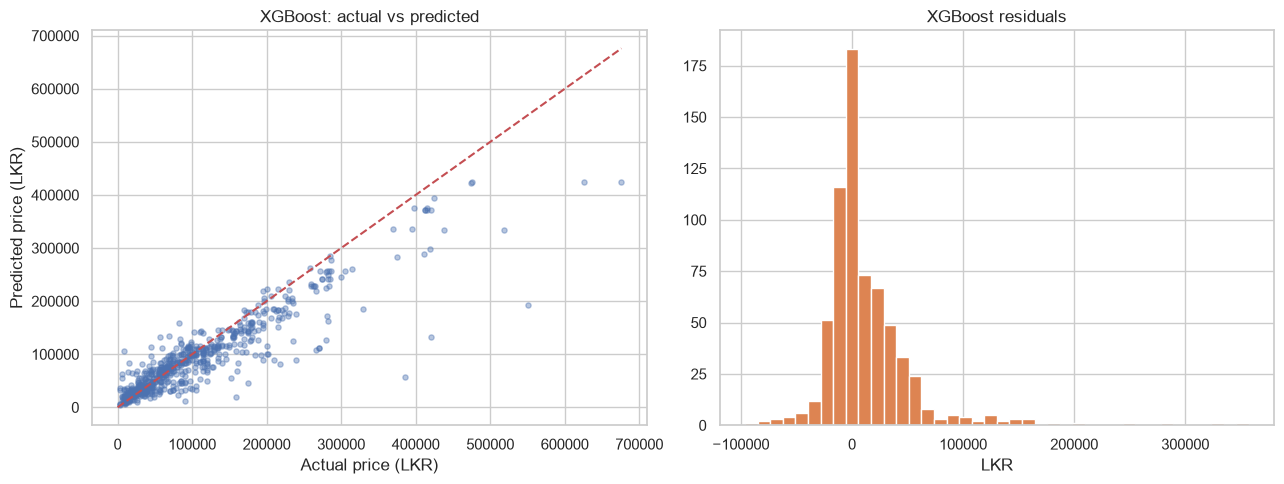

In [6]:
xgb = fitted["XGBoost"]; pred = xgb.predict(X_va)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_va, pred, alpha=.4, s=14); lim = [0, max(y_va.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (LKR)"); ax[0].set_ylabel("Predicted price (LKR)"); ax[0].set_title("XGBoost: actual vs predicted")
ax[1].hist(y_va - pred, bins=40, color="#DD8452"); ax[1].set_title("XGBoost residuals"); ax[1].set_xlabel("LKR")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "04_xgb_actual_vs_pred.png", dpi=150); plt.show()

## 3. Boosting rounds: training error keeps falling, validation error flattens
 examines how the number of boosting rounds affects XGBoost performance. It trains models with different numbers of rounds and compares their training and validation MAE using a line graph.

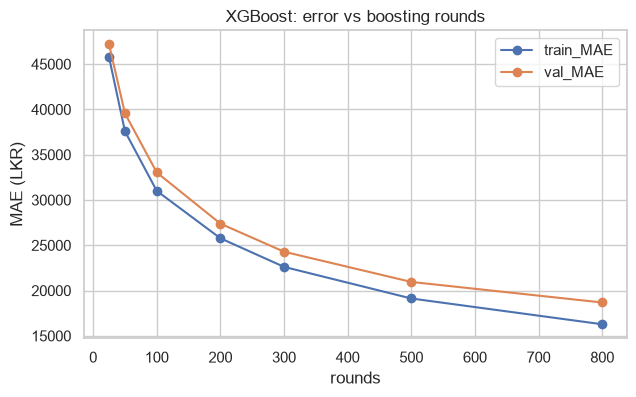

,rounds,train_MAE,val_MAE
0,25,"45,754.69","47,188.84"
1,50,"37,579.49","39,556.78"
2,100,"31,002.64","33,033.92"
3,200,"25,770.23","27,384.24"
4,300,"22,612.97","24,286.86"
5,500,"19,123.71","20,951.18"
6,800,"16,277.85","18,681.98"


In [7]:
rows = []
for k in [25, 50, 100, 200, 300, 500, 800]:
    m = M.make_xgboost(n_estimators=k).fit(X_tr, y_tr)
    rows.append({"rounds": k, "train_MAE": regression_metrics(y_tr, m.predict(X_tr))["MAE"],
                 "val_MAE": regression_metrics(y_va, m.predict(X_va))["MAE"]})
curve = pd.DataFrame(rows)
curve.plot(x="rounds", y=["train_MAE", "val_MAE"], marker="o", figsize=(7, 4))
plt.ylabel("MAE (LKR)"); plt.title("XGBoost: error vs boosting rounds")
plt.savefig(config.PLOT_DIR / "04_xgb_rounds_curve.png", dpi=150); plt.show()
curve

## 4. Feature importance of each booster
compares the feature importance of the available boosting models. It identifies which features contribute most to the predictions and displays the results in a comparison chart.

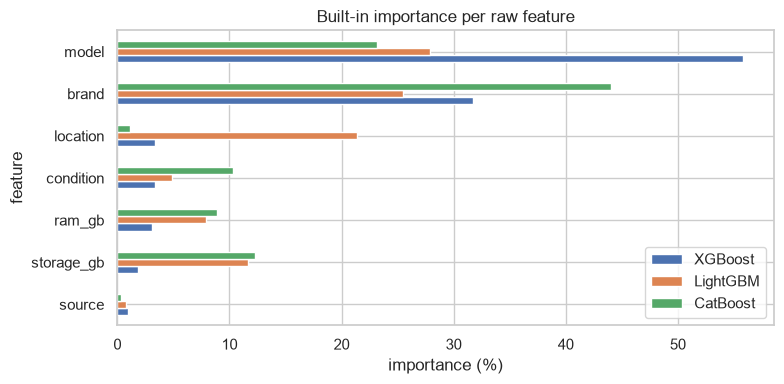

,XGBoost,LightGBM,CatBoost
feature,,,
model,55.78,27.87,23.12
brand,31.73,25.52,43.99
location,3.36,21.42,1.14
condition,3.32,4.88,10.35
ram_gb,3.08,7.89,8.84
storage_gb,1.81,11.68,12.27
source,0.91,0.75,0.28


In [8]:
from src.explain import grouped_importance
imps = pd.concat({n: grouped_importance(m).set_index("feature")["importance_%"] for n, m in fitted.items()}, axis=1).fillna(0)
imps.sort_values(imps.columns[0]).plot.barh(figsize=(8, 4)); plt.xlabel("importance (%)")
plt.title("Built-in importance per raw feature"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "04_booster_importance.png", dpi=150); plt.show()
imps

## Notes

- **Best booster:** LightGBM performed best (MAE Rs. 21,888, R² 0.82), while XGBoost was the fastest to train.
- **Boosting vs Random Forest:** All boosters performed worse than Random Forest with default settings. However, XGBoost improved significantly with more rounds, showing that additional tuning could improve performance.
- **Over-fitting:** Training and validation errors are relatively close, suggesting the boosters are more under-fitted than over-fitted.
- **Feature importance:** Brand and model are the most important features for XGBoost and CatBoost. LightGBM distributes importance more evenly. Source has very little impact across all three models.